In [1]:
#Install packages and import libraries

!pip -q install arch pmdarima openpyxl

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from pmdarima import auto_arima
from arch import arch_model

from statsmodels.stats.diagnostic import (
    het_arch,
    acorr_ljungbox
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
#Upload datasets

uploaded = files.upload()

indore_file = next(
    (f for f in uploaded if "indore" in f.lower()),
    None
)

gondal_file = next(
    (f for f in uploaded if "rajkot" in f.lower()),
    None
)

if indore_file is None or gondal_file is None:
    raise ValueError(
        "Upload both files: the Indore CSV and Gondal/Rajkot Excel file."
    )

print("Indore file:", indore_file)
print("Gondal file:", gondal_file)

Saving price_data_cleaned_rajkot.xlsx to price_data_cleaned_rajkot.xlsx
Saving price_indore_market_cleaned_ffill_no_holidays_covid.csv to price_indore_market_cleaned_ffill_no_holidays_covid.csv
Indore file: price_indore_market_cleaned_ffill_no_holidays_covid.csv
Gondal file: price_data_cleaned_rajkot.xlsx


In [3]:
#Create a data-cleaning function

def prepare_market_data(filename, market_label):
    if filename.lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(filename)
    else:
        df = pd.read_csv(filename)

    # Handle different date-column names
    date_col = next(
        (c for c in df.columns if c.lower() == "date"),
        None
    )

    if date_col is None:
        raise ValueError(f"No date column found in {filename}")

    if "p_modal" not in df.columns:
        raise ValueError(f"No p_modal column found in {filename}")

    df[date_col] = pd.to_datetime(
        df[date_col], errors="coerce"
    )

    df["p_modal"] = pd.to_numeric(
        df["p_modal"], errors="coerce"
    )

    df = df.dropna(subset=[date_col, "p_modal"])
    df = df[df["p_modal"] > 0]

    # Sort by date and remove duplicate dates
    df = df.sort_values(date_col)
    df = df.drop_duplicates(subset=[date_col], keep="last")

    price = df.set_index(date_col)["p_modal"].astype(float)
    price.name = market_label

    print(f"\n{market_label}")
    print("Observations:", len(price))
    print("Start date:", price.index.min())
    print("End date:", price.index.max())
    print("Missing prices:", price.isna().sum())

    return price


indore_price = prepare_market_data(
    indore_file, "Indore"
)

gondal_price = prepare_market_data(
    gondal_file, "Gondal"
)


Indore
Observations: 4386
Start date: 2011-01-01 00:00:00
End date: 2025-12-31 00:00:00
Missing prices: 0

Gondal
Observations: 4354
Start date: 2011-01-03 00:00:00
End date: 2025-12-31 00:00:00
Missing prices: 0


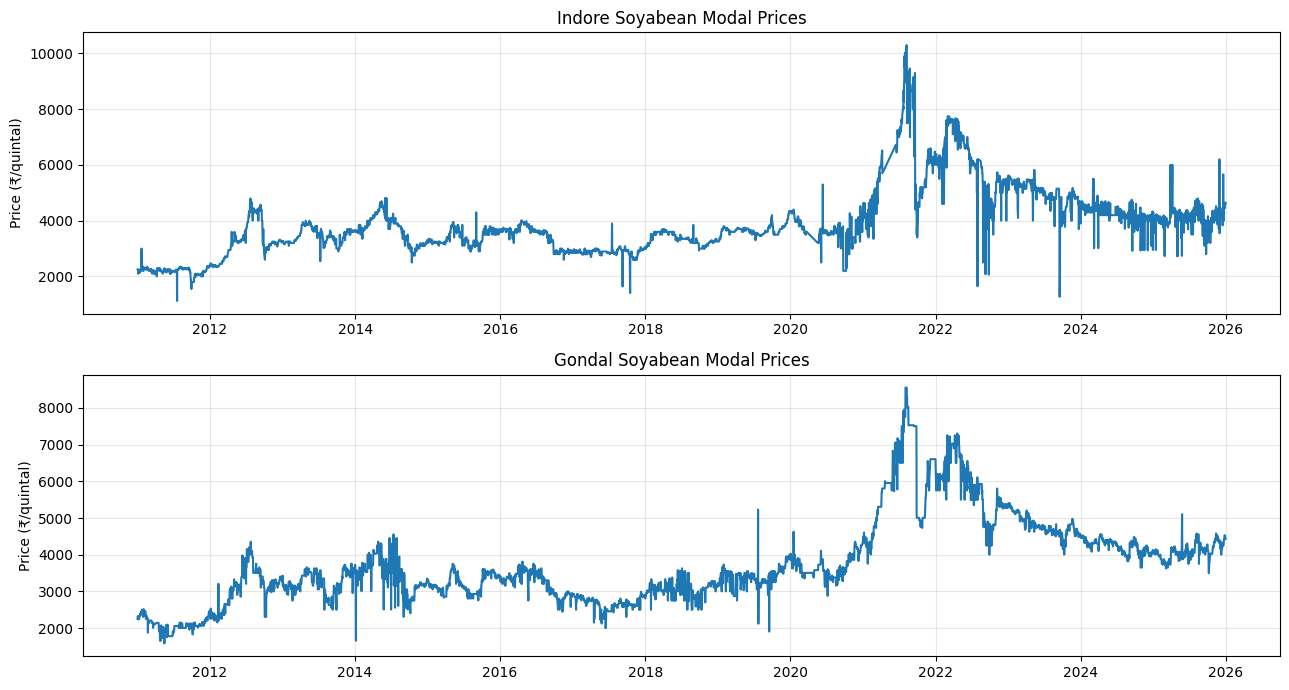

In [5]:
#Plot and inspect both price series

fig, axes = plt.subplots(2, 1, figsize=(13, 7))

axes[0].plot(indore_price.index, indore_price.values)
axes[0].set_title("Indore Soyabean Modal Prices")
axes[0].set_ylabel("Price (₹/quintal)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(gondal_price.index, gondal_price.values)
axes[1].set_title("Gondal Soyabean Modal Prices")
axes[1].set_ylabel("Price (₹/quintal)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
#Define the ARCH/GARCH analysis function

def run_arch_garch(price, market_name, forecast_horizon=10):

    print("\n" + "=" * 70)
    print(f"ARCH / GARCH ANALYSIS: {market_name}")
    print("=" * 70)

    # --------------------------------------------------
    # 1. Train/test split
    # --------------------------------------------------
    cut = int(len(price) * 0.80)

    train = price.iloc[:cut]
    test = price.iloc[cut:]

    print("\n1. DATA SPLIT")
    print("Training observations:", len(train))
    print("Testing observations:", len(test))
    print("Training period:", train.index.min(), "to", train.index.max())
    print("Testing period:", test.index.min(), "to", test.index.max())

    # --------------------------------------------------
    # 2. Fit ARIMA to training prices
    # --------------------------------------------------
    print("\n2. FITTING ARIMA")

    arima = auto_arima(
        train.to_numpy(),
        seasonal=False,
        max_p=3,
        max_q=3,
        max_d=2,
        stepwise=True,
        suppress_warnings=True,
        error_action="ignore"
    )

    print("Selected ARIMA order:", arima.order)
    print(arima.summary())

    # --------------------------------------------------
    # 3. Extract residuals
    # --------------------------------------------------
    resid = pd.Series(
        np.asarray(arima.resid()).reshape(-1)
    ).dropna()

    print("\n3. ARIMA RESIDUALS")
    print("Residual count:", len(resid))

    plt.figure(figsize=(12, 3))
    plt.plot(resid)
    plt.title(f"{market_name}: ARIMA Residuals")
    plt.xlabel("Training observation")
    plt.ylabel("Residual")
    plt.grid(True, alpha=0.3)
    plt.show()

    # --------------------------------------------------
    # 4. ARCH-LM test
    # --------------------------------------------------
    print("\n4. ARCH-LM TEST")

    lm_stat, lm_pvalue, f_stat, f_pvalue = het_arch(
        resid, nlags=5
    )

    print("LM statistic:", round(lm_stat, 4))
    print("LM p-value:", round(lm_pvalue, 6))
    print("F statistic:", round(f_stat, 4))
    print("F p-value:", round(f_pvalue, 6))

    if lm_pvalue < 0.05:
        print("Conclusion: Evidence of ARCH effects.")
    else:
        print("Conclusion: No significant ARCH effects detected.")

    # --------------------------------------------------
    # 5. Fit ARCH(1)
    # --------------------------------------------------
    print("\n5. ARCH(1) MODEL")

    arch_fit = arch_model(
        resid,
        mean="Zero",
        vol="ARCH",
        p=1,
        dist="normal",
        rescale=False
    ).fit(disp="off")

    print(arch_fit.summary())

    # --------------------------------------------------
    # 6. Fit GARCH(1,1)
    # --------------------------------------------------
    print("\n6. GARCH(1,1) MODEL")

    garch_fit = arch_model(
        resid,
        mean="Zero",
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        rescale=False
    ).fit(disp="off")

    print(garch_fit.summary())

    # --------------------------------------------------
    # 7. Compare models
    # --------------------------------------------------
    print("\n7. MODEL COMPARISON")

    comparison = pd.DataFrame({
        "Market": [market_name, market_name],
        "Model": ["ARCH(1)", "GARCH(1,1)"],
        "AIC": [arch_fit.aic, garch_fit.aic],
        "BIC": [arch_fit.bic, garch_fit.bic],
        "Log likelihood": [
            arch_fit.loglikelihood,
            garch_fit.loglikelihood
        ],
        "Converged": [
            arch_fit.convergence_flag == 0,
            garch_fit.convergence_flag == 0
        ]
    })

    print(comparison.round(4).to_string(index=False))

    if garch_fit.aic < arch_fit.aic:
        print("AIC comparison: GARCH(1,1) is preferred.")
    else:
        print("AIC comparison: ARCH(1) has the lower AIC.")

    # --------------------------------------------------
    # 8. GARCH diagnostic tests
    # --------------------------------------------------
    print("\n8. GARCH DIAGNOSTICS")

    standardized_resid = pd.Series(
        np.asarray(garch_fit.std_resid)
    ).replace([np.inf, -np.inf], np.nan).dropna()

    # Test standardized residuals for autocorrelation
    print("\nLjung-Box test on standardized residuals:")
    print(
        acorr_ljungbox(
            standardized_resid,
            lags=[10],
            return_df=True
        )
    )

    # Test squared standardized residuals
    print("\nLjung-Box test on squared standardized residuals:")
    print(
        acorr_ljungbox(
            standardized_resid ** 2,
            lags=[10],
            return_df=True
        )
    )

    # Test remaining ARCH effects
    remaining_arch = het_arch(
        standardized_resid, nlags=5
    )

    print(
        "\nARCH-LM p-value after GARCH:",
        round(remaining_arch[1], 6)
    )

    if remaining_arch[1] < 0.05:
        print("Warning: Remaining ARCH effects may be present.")
    else:
        print("No significant remaining ARCH effects detected.")

    # --------------------------------------------------
    # 9. Plot conditional volatility
    # --------------------------------------------------
    print("\n9. CONDITIONAL VOLATILITY")

    volatility = pd.Series(
        np.asarray(garch_fit.conditional_volatility),
        index=train.index[-len(garch_fit.conditional_volatility):]
    )

    plt.figure(figsize=(12, 4))
    plt.plot(volatility.index, volatility.values)
    plt.title(f"{market_name}: GARCH(1,1) Conditional Volatility")
    plt.xlabel("Date")
    plt.ylabel("Conditional standard deviation (₹/quintal)")
    plt.grid(True, alpha=0.3)
    plt.show()

    # --------------------------------------------------
    # 10. ARIMA price forecasts
    # --------------------------------------------------
    print("\n10. TEST-PERIOD PRICE FORECAST")

    pred = pd.Series(
        np.asarray(arima.predict(n_periods=len(test))),
        index=test.index
    )

    rmse = np.sqrt(mean_squared_error(test, pred))
    mae = mean_absolute_error(test, pred)
    mape = np.mean(
        np.abs((test.to_numpy() - pred.to_numpy()) /
               test.to_numpy())
    ) * 100

    print("RMSE:", round(rmse, 3))
    print("MAE:", round(mae, 3))
    print("MAPE (%):", round(mape, 3))

    plt.figure(figsize=(12, 4))
    plt.plot(train.index, train.values, label="Training prices")
    plt.plot(test.index, test.values, label="Actual test prices")
    plt.plot(pred.index, pred.values, label="ARIMA forecasts")
    plt.title(f"{market_name}: Actual Prices vs ARIMA Forecasts")
    plt.xlabel("Date")
    plt.ylabel("Price (₹/quintal)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # --------------------------------------------------
    # 11. Forecast conditional volatility
    # --------------------------------------------------
    print("\n11. FUTURE GARCH VOLATILITY FORECAST")

    forecast = garch_fit.forecast(
        horizon=forecast_horizon,
        reindex=False
    )

    variance_forecast = forecast.variance.iloc[-1].to_numpy()
    sd_forecast = np.sqrt(variance_forecast)

    volatility_forecast = pd.DataFrame({
        "Horizon": np.arange(1, forecast_horizon + 1),
        "Forecast_variance": variance_forecast,
        "Forecast_SD": sd_forecast
    })

    print(volatility_forecast.round(4).to_string(index=False))

    # --------------------------------------------------
    # 12. Save results for this market
    # --------------------------------------------------
    comparison.to_csv(
        f"{market_name.lower()}_model_comparison.csv",
        index=False
    )

    volatility_forecast.to_csv(
        f"{market_name.lower()}_volatility_forecast.csv",
        index=False
    )

    return {
        "market": market_name,
        "arima": arima,
        "arch_fit": arch_fit,
        "garch_fit": garch_fit,
        "arch_lm_stat": lm_stat,
        "arch_lm_pvalue": lm_pvalue,
        "comparison": comparison,
        "volatility": volatility,
        "volatility_forecast": volatility_forecast,
        "price_rmse": rmse,
        "price_mae": mae,
        "price_mape": mape,
        "garch_arch_pvalue": remaining_arch[1]
    }


ARCH / GARCH ANALYSIS: Indore

1. DATA SPLIT
Training observations: 3508
Testing observations: 878
Training period: 2011-01-01 00:00:00 to 2023-02-11 00:00:00
Testing period: 2023-02-13 00:00:00 to 2025-12-31 00:00:00

2. FITTING ARIMA
Selected ARIMA order: (2, 1, 3)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 3508
Model:               SARIMAX(2, 1, 3)   Log Likelihood              -24349.841
Date:                Sat, 24 Oct 2026   AIC                          48711.682
Time:                        17:50:38   BIC                          48748.657
Sample:                             0   HQIC                         48724.876
                               - 3508                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------

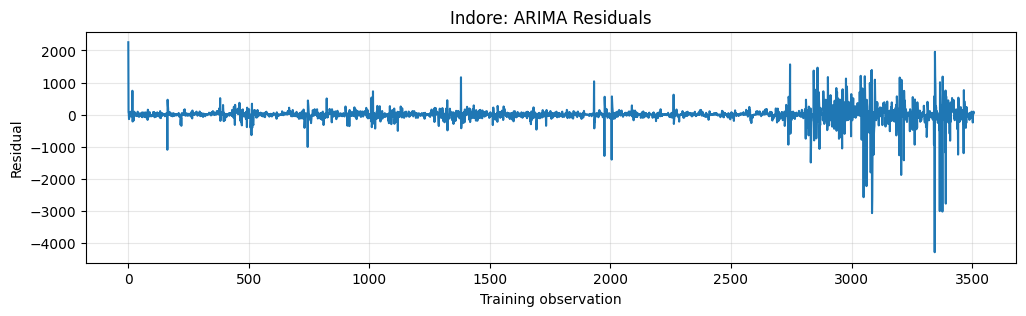


4. ARCH-LM TEST
LM statistic: 294.6186
LM p-value: 0.0
F statistic: 64.2244
F p-value: 0.0
Conclusion: Evidence of ARCH effects.

5. ARCH(1) MODEL
                        Zero Mean - ARCH Model Results                        
Dep. Variable:                   None   R-squared:                       0.000
Mean Model:                 Zero Mean   Adj. R-squared:                  0.000
Vol Model:                       ARCH   Log-Likelihood:               -23295.5
Distribution:                  Normal   AIC:                           46595.0
Method:            Maximum Likelihood   BIC:                           46607.4
                                        No. Observations:                 3508
Date:                Sat, Oct 24 2026   Df Residuals:                     3508
Time:                        17:50:38   Df Model:                            0
                              Volatility Model                              
                 coef    std err          t      P>|t|      95.0

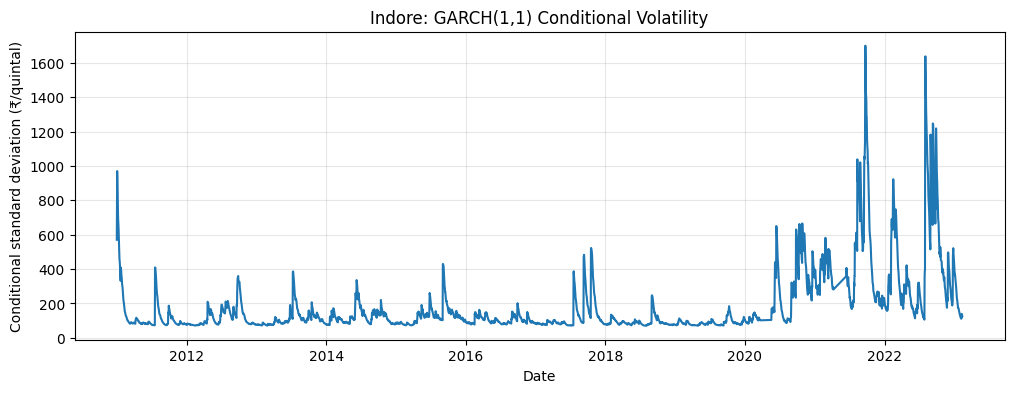


10. TEST-PERIOD PRICE FORECAST
RMSE: 1098.462
MAE: 971.052
MAPE (%): 24.29


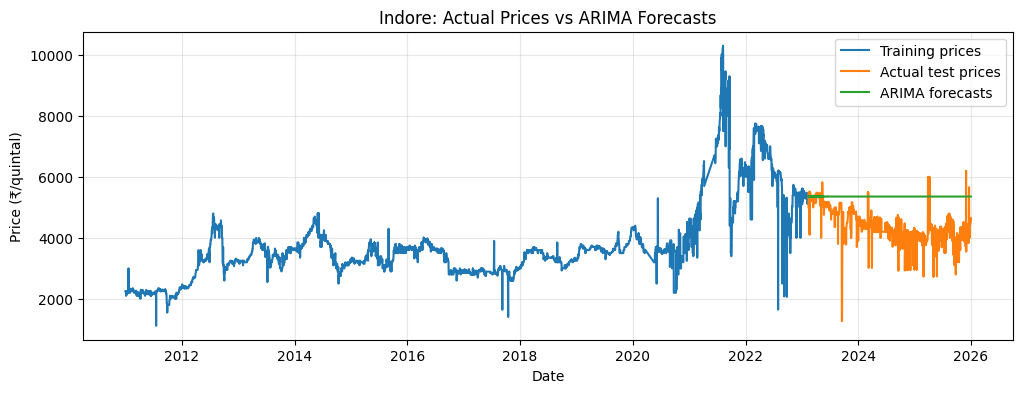


11. FUTURE GARCH VOLATILITY FORECAST
 Horizon  Forecast_variance  Forecast_SD
       1         14932.1310     122.1971
       2         15550.9176     124.7033
       3         16169.7041     127.1602
       4         16788.4906     129.5704
       5         17407.2771     131.9366
       6         18026.0636     134.2612
       7         18644.8501     136.5461
       8         19263.6367     138.7935
       9         19882.4232     141.0050
      10         20501.2097     143.1824


In [7]:
# Run the analysis for Indore

indore_results = run_arch_garch(
    indore_price,
    market_name="Indore",
    forecast_horizon=10
)


ARCH / GARCH ANALYSIS: Gondal

1. DATA SPLIT
Training observations: 3483
Testing observations: 871
Training period: 2011-01-03 00:00:00 to 2023-01-03 00:00:00
Testing period: 2023-01-04 00:00:00 to 2025-12-31 00:00:00

2. FITTING ARIMA
Selected ARIMA order: (1, 1, 3)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 3483
Model:               SARIMAX(1, 1, 3)   Log Likelihood              -23271.356
Date:                Sat, 24 Oct 2026   AIC                          46554.712
Time:                        17:52:03   BIC                          46591.644
Sample:                             0   HQIC                         46567.896
                               - 3483                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------

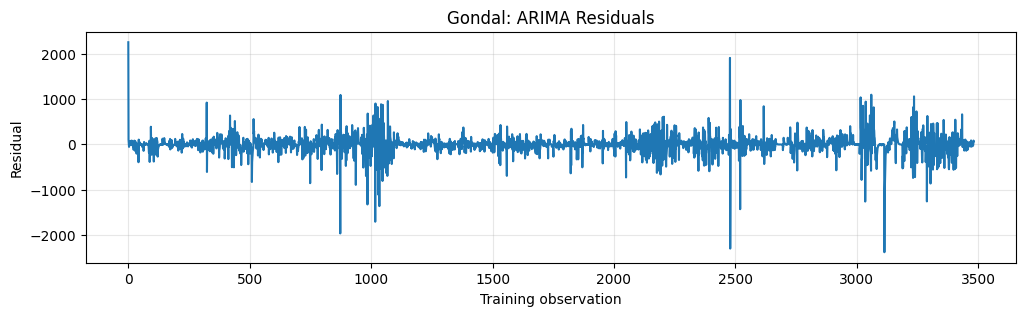


4. ARCH-LM TEST
LM statistic: 356.2584
LM p-value: 0.0
F statistic: 79.2461
F p-value: 0.0
Conclusion: Evidence of ARCH effects.

5. ARCH(1) MODEL
                        Zero Mean - ARCH Model Results                        
Dep. Variable:                   None   R-squared:                       0.000
Mean Model:                 Zero Mean   Adj. R-squared:                  0.000
Vol Model:                       ARCH   Log-Likelihood:               -22973.0
Distribution:                  Normal   AIC:                           45950.0
Method:            Maximum Likelihood   BIC:                           45962.3
                                        No. Observations:                 3483
Date:                Sat, Oct 24 2026   Df Residuals:                     3483
Time:                        17:52:03   Df Model:                            0
                              Volatility Model                              
                 coef    std err          t      P>|t|      95.0

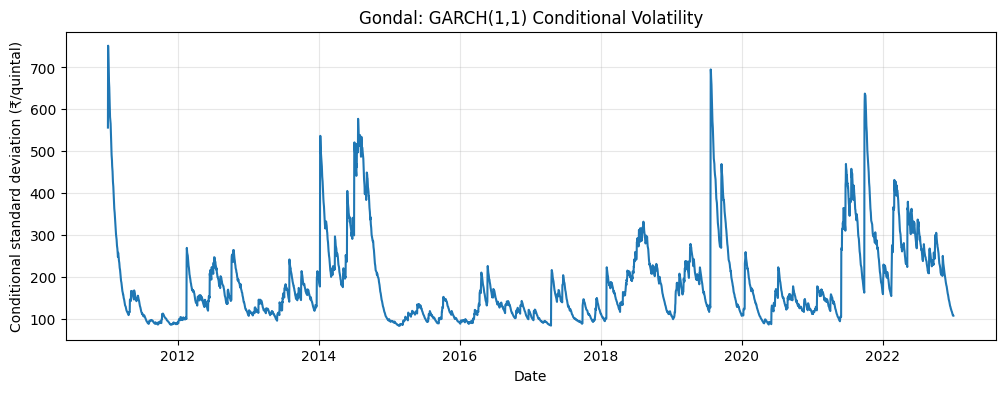


10. TEST-PERIOD PRICE FORECAST
RMSE: 1475.279
MAE: 1364.209
MAPE (%): 32.476


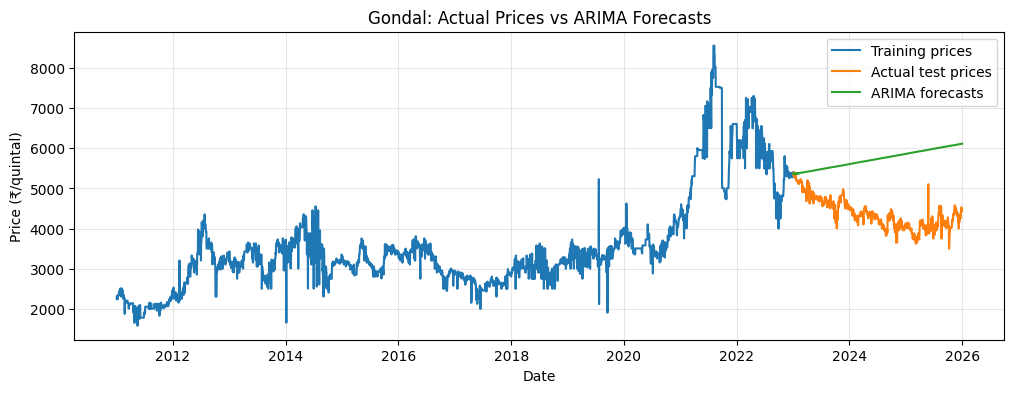


11. FUTURE GARCH VOLATILITY FORECAST
 Horizon  Forecast_variance  Forecast_SD
       1         11347.0211     106.5224
       2         11630.0181     107.8426
       3         11912.3286     109.1436
       4         12193.9541     110.4262
       5         12474.8963     111.6911
       6         12755.1570     112.9387
       7         13034.7377     114.1698
       8         13313.6400     115.3847
       9         13591.8657     116.5842
      10         13869.4164     117.7685


In [8]:
# Run the analysis for Gondal
gondal_results = run_arch_garch(
    gondal_price,
    market_name="Gondal",
    forecast_horizon=10
)

In [9]:
#Compare both markets side by side

summary = pd.DataFrame([
    {
        "Market": r["market"],
        "ARIMA order": str(r["arima"].order),
        "ARCH-LM statistic": r["arch_lm_stat"],
        "ARCH-LM p-value": r["arch_lm_pvalue"],
        "ARCH AIC": r["arch_fit"].aic,
        "GARCH AIC": r["garch_fit"].aic,
        "ARCH BIC": r["arch_fit"].bic,
        "GARCH BIC": r["garch_fit"].bic,
        "GARCH residual ARCH p-value": r["garch_arch_pvalue"],
        "Price RMSE": r["price_rmse"],
        "Price MAE": r["price_mae"],
        "Price MAPE (%)": r["price_mape"]
    }
    for r in [indore_results, gondal_results]
])

print(summary.round(4).to_string(index=False))
summary.to_csv("arch_garch_both_markets_summary.csv", index=False)

Market ARIMA order  ARCH-LM statistic  ARCH-LM p-value   ARCH AIC  GARCH AIC   ARCH BIC  GARCH BIC  GARCH residual ARCH p-value  Price RMSE  Price MAE  Price MAPE (%)
Indore   (2, 1, 3)           294.6186              0.0 46595.0385 44598.6680 46607.3641 44617.1564                       0.3777   1098.4617   971.0518         24.2895
Gondal   (1, 1, 3)           356.2584              0.0 45949.9664 45393.4535 45962.2777 45411.9205                       0.0521   1475.2791  1364.2087         32.4761


In [10]:
# Download the final summary
files.download("arch_garch_both_markets_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>